<a href="https://colab.research.google.com/github/polly-esp/Machine-Learning/blob/main/ML_group_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imports

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.calibration import column_or_1d
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.tree import DecisionTreeRegressor
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn import metrics

### DATA

In [ ]:
kwb_data_2019 = pd.read_excel("kwb-2019.xls")
health_report_data = pd.read_csv("2019_data.csv", sep=";")

In [ ]:
# Renambe gwb column in health data
health_report_data["gwb_code_10"] = health_report_data["RegioS"]

In [ ]:
# Construct dataset
df = health_report_data.merge(kwb_data_2019, on="gwb_code_10")

In [ ]:
df["target"] = df["PrevalentieDementie_20"] / df["a_inw"]
df = df.drop(columns=["PrevalentieDementie_20"])

In [ ]:
df.drop_duplicates()

,ID,RegioS,Perioden,OvermatigAlcoholgebruik_1,RokenSoms_2,Eenzaamheid_13,PrevalentieStemmingsstoornissen_25,gwb_code_10,gwb_code_8,regio,...,g_afs_sc,g_3km_sc,a_opp_ha,a_lan_ha,a_wat_ha,pst_mvp,pst_dekp,ste_mvs,ste_oad,target
0,852,GM1680,2019JJ00,6.4,16.3,41.1,883,GM1680,1680,Aa en Hunze,...,"1,2","1,8",27887,27609,279,.,.,5,280,0.012684
1,884,GM0358,2019JJ00,9.3,19.4,37.2,1032,GM0358,358,Aalsmeer,...,"0,8","4,0",3229,2012,1217,.,.,4,921,0.010306
2,900,GM0197,2019JJ00,6.9,17.8,38.8,896,GM0197,197,Aalten,...,"0,8","4,6",9705,9654,52,.,.,4,782,0.011477
3,916,GM0059,2019JJ00,8.6,20.5,42.6,888,GM0059,59,Achtkarspelen,...,"0,7","3,5",10398,10223,175,.,.,5,427,0.009550
4,932,GM0482,2019JJ00,4.4,17.1,43.6,629,GM0482,482,Alblasserdam,...,"0,5","6,0",1006,878,128,.,.,2,1512,0.011261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,6852,GM0879,2019JJ00,9.3,14.6,48.1,742,GM0879,879,Zundert,...,"1,2","2,2",12121,12065,56,.,.,4,540,0.011429
342,6868,GM0301,2019JJ00,7.5,17.3,42.3,1597,GM0301,301,Zutphen,...,"0,6","11,3",4293,4095,198,.,.,2,1633,0.010586
343,6884,GM1896,2019JJ00,7.6,19.2,37.8,677,GM1896,1896,Zwartewaterland,...,"0,7","5,0",8786,8249,537,.,.,4,719,0.007999
344,6900,GM0642,2019JJ00,5.0,18.9,46.9,1478,GM0642,642,Zwijndrecht,...,"0,5","10,3",2277,2030,247,.,.,2,2060,0.012702


In [ ]:
def fix_str_to_float(df, excecption_cols=["gwb_code_10", "regio", "gm_naam", "recs", "gwb_code", "ind_wbi"]):
    cols_to_proc = df.select_dtypes("object").columns
    cols_to_proc = [i for i in cols_to_proc if i not in excecption_cols]
    for col in cols_to_proc:
        try:
            df[col] = df[col].astype(float)
        except:
            print("Failed to proc", col)
            try:
                df[col] = df[col].apply(lambda x: 0.0 if x == "." else float(x))
            except:
                print("Failed to proc", col)
                try:
                    df[col] = df[col].apply(lambda x: 0.0 if x.replace(",", ".") == "." else float(x.replace(",", ".")))
                except:
                    print("final fail for ", col)
                    df = df.drop(columns=[col])

    return df


In [ ]:

def convert_rel_char(df):
    inhab_groups = [
        "a_man",
        "a_vrouw",
        "a_00_14",
        "a_15_24",
        "a_25_44",
        "a_45_64",
        "a_65_oo",
        "a_ongeh",
        "a_gehuwd",
        "a_gesch",
        "a_verwed",
        "a_w_all",
        "a_nw_all",
        "a_ov_nw",
        "a_ste",
        "a_geb",
        "a_inkont",
        "a_soz_wb",
        "a_soz_ao",
        "a_soz_ww",
        "a_soz_ow",
        "a_m2w",
        "a_pau",
        "a_bst_nb"
    ]
    for g in inhab_groups:
        df[g] = df[g].astype(float) / df["a_inw"]

    household_groups = [
        "a_1p_hh",
        "a_hh_z_k",
        "a_bst_b",
        "a_hh_m_k",
    ]

    for g in household_groups:
        df[g] = df[g].astype(float) / df["a_hh"]

    business_groups = ["a_bed_a", "a_bed_bf", "a_bed_gi", "a_bed_hj", "a_bed_kl", "a_bed_mn", "a_bed_ru"]

    for g in business_groups:
        df[g] = df[g].astype(float) / df["a_bedv"]

    cars_groups = ["a_bst_b", "a_bst_nb", "a_m2w"]

    for g in cars_groups:
        df[g] = df[g].astype(float) / df["a_pau"]

    land_groups = ["a_lan_ha", "a_wat_ha"]

    for g in land_groups:
        df[g] = df[g].astype(float) / df["a_opp_ha"]

    electricity_consumption_groups = [
        "g_ele",
        "g_ele_ap",
        "g_ele_tw",
        "g_ele_hw",
        "g_ele_2w",
        "g_ele_vw",
        "g_ele_hu",
        "g_ele_ko",
    ]

    for g in electricity_consumption_groups:
        df[g] = df[g].astype(float) / df["a_woning"]

    gas_consumption_groups = [
        "g_gas",
        "g_gas_ap",
        "g_gas_tw",
        "g_gas_hw",
        "g_gas_2w",
        "g_gas_vw",
        "g_gas_hu",
        "g_gas_ko",
    ]

    for g in gas_consumption_groups:
        df[g] = df[g].astype(float) / df["a_woning"]

    df["percent built areas"] = df["a_bst_b"] / df["a_bst_b"].astype(float) / (df["a_bst_b"] + df["a_bst_nb"])
    df["percent not-built areas"] = df["a_bst_nb"] / df["a_bst_nb"].astype(float) / (df["a_bst_b"] + df["a_bst_nb"])

    df['PrevalentieStemmingsstoornissen_25'] = df['PrevalentieStemmingsstoornissen_25'].astype(float) / df['a_inw']

    rivm_columns_to_convert_100 = [

       'OvermatigAlcoholgebruik_1',
       'RokenSoms_2',
       'Eenzaamheid_13',
    ]

    for g in rivm_columns_to_convert_100:
        if g in df.columns:
            df[g] = df[g].astype(float) / 100

    columns_100 =[
            'g_hhgro',
            'bev_dich',
            'a_woning',
            'g_woz',
            'p_1gezw',
            'p_mgezw',
            'p_bewndw',
            'p_leegsw',
            'p_koopw',
            'p_huurw',
            'p_wcorpw',
            'p_ov_hw',
            'p_e_o_w',
            'p_bjj2k',
            'g_pau_km',
            'ste_oad',
            'p_bjo2k',
            'g_pau_hh',
            'g_afs_hp',
            'g_afs_gs',
            'g_afs_kv',
            'g_afs_sc',
            'g_3km_sc',
            'ste_oad',
            'p_geb',
            'p_ste'
    ]

    for g in columns_100:
        df[g]=df[g].astype(float)/ 100

    df = df.drop(
        columns=[
            "a_opp_ha",
            "a_pau",
            'a_woning',
            "a_bedv",
            "a_inw",
            "a_hh",
            "a_marok",
            "a_antaru",
            "a_suri",
            "a_tur",

        ]
    )

    return df

In [ ]:
df["g_pau_hh"].apply(lambda x: 0.0 if x.replace(",", ".") == "." else float(x.replace(",", ".")))

,g_pau_hh
0,1.3
1,1.3
2,1.2
3,1.3
4,1.1
...,...
341,1.3
342,1.0
343,1.3
344,1.1


In [ ]:
df = fix_str_to_float(df)

Failed to proc RegioS
Failed to proc RegioS
final fail for  RegioS
Failed to proc Perioden
Failed to proc Perioden
final fail for  Perioden
Failed to proc g_hhgro
Failed to proc g_hhgro
Failed to proc g_woz
Failed to proc g_gas_ap
Failed to proc p_stadsv
Failed to proc g_pau_hh
Failed to proc g_pau_hh
Failed to proc g_pau_km
Failed to proc g_afs_hp
Failed to proc g_afs_hp
Failed to proc g_afs_gs
Failed to proc g_afs_gs
Failed to proc g_afs_kv
Failed to proc g_afs_kv
Failed to proc g_afs_sc
Failed to proc g_afs_sc
Failed to proc g_3km_sc
Failed to proc g_3km_sc
Failed to proc pst_mvp
Failed to proc pst_dekp


In [ ]:
df = convert_rel_char(df)

In [ ]:
df = df.dropna(axis=1, how='all')

In [ ]:
numeric_columns = df.select_dtypes(include=["float64", "int64"]).columns
df_numeric = df[numeric_columns]

imputer = IterativeImputer(estimator=DecisionTreeRegressor(), max_iter=10, random_state=0)
imputed_data = imputer.fit_transform(df_numeric)

imputed_df_numeric = pd.DataFrame(imputed_data, columns=df_numeric.columns)


df_non_numeric = df.select_dtypes(exclude=["float64", "int64"])
df = pd.concat([imputed_df_numeric, df_non_numeric], axis=1)

In [ ]:
features = [
    i
    for i in df.select_dtypes("number").columns
    if i
    not in [
        "target",
        "gwb_code_8",
        "ID",
        "g_vernoo",
        "g_wodief",
        "g_gewsek",
        "PrevalentieDementie_20",

    ]
]

In [ ]:
features.remove('p_ste')
features.remove('p_geb')

In [ ]:
len(features)

83

In [ ]:
df.to_csv('imputed.csv', index=False)

In [ ]:
# target = df["target"]
target = "target"

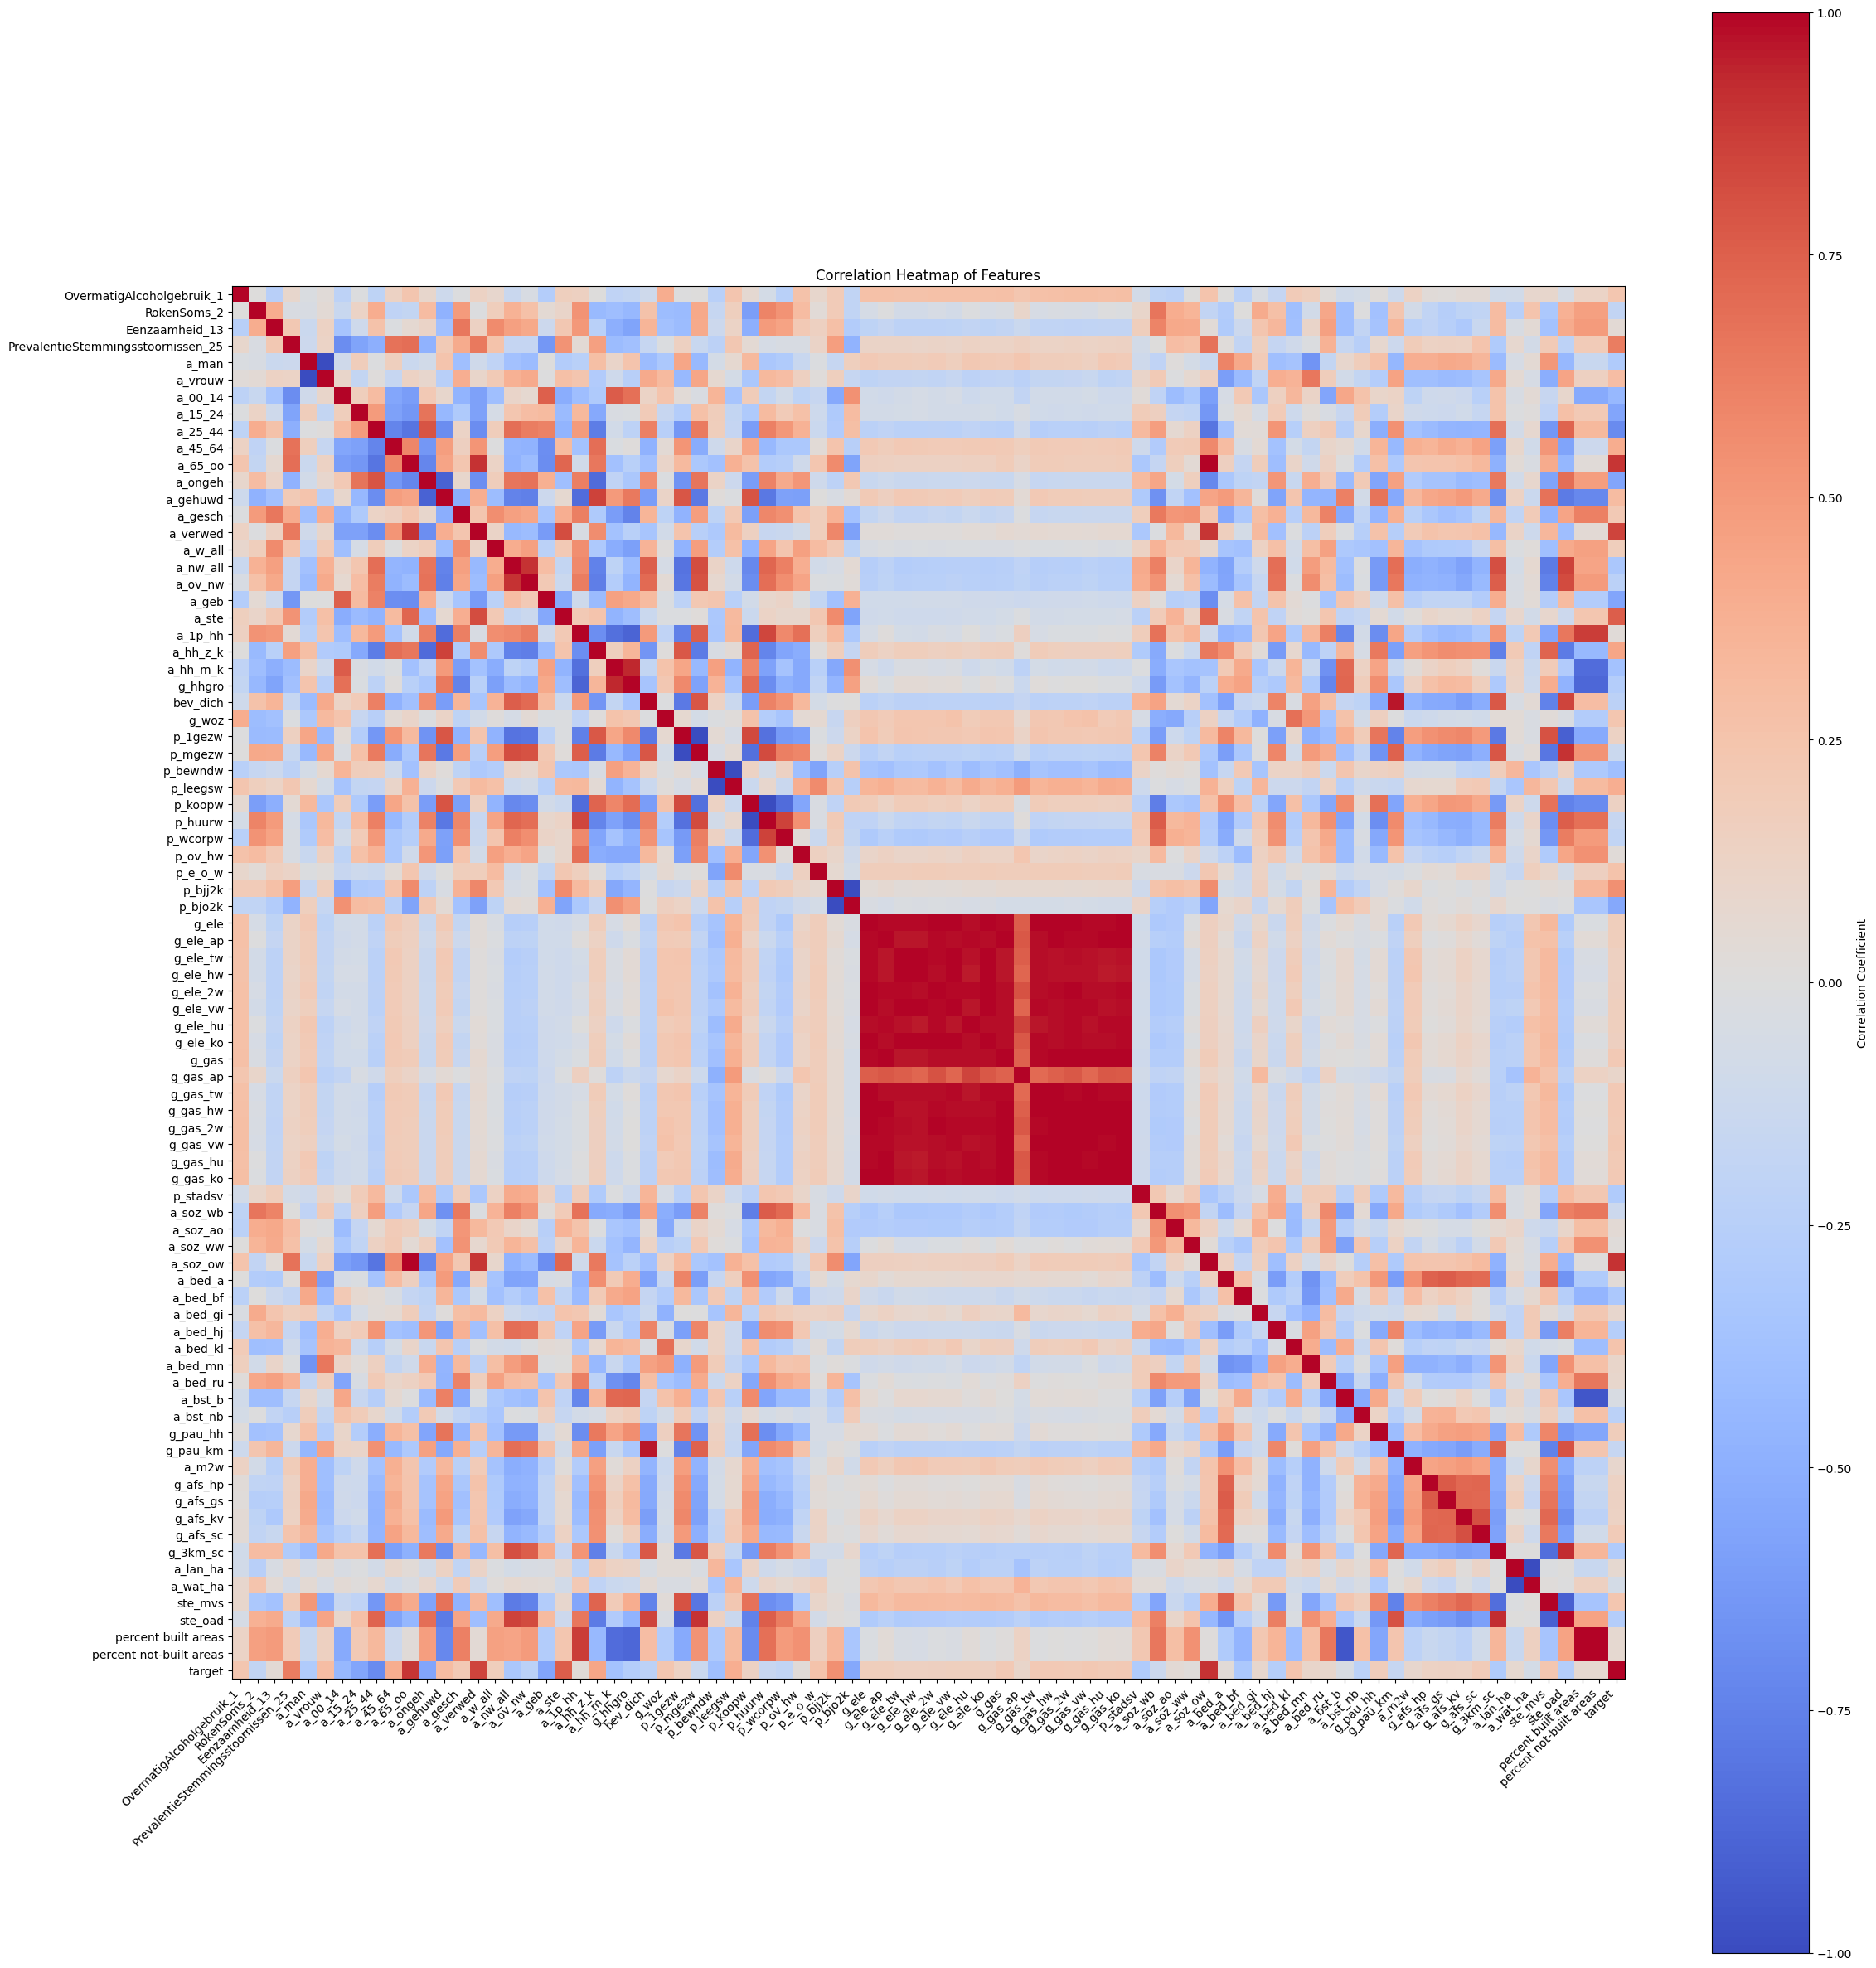

In [ ]:
correlation_matrix = df[features + [target]].corr().dropna(how="all").dropna(how="all", axis=1)
# correlation_matrix = correlation_matrix.sort_values(by=target)

# Plot heatmap
plt.figure(figsize=(24, 24))
plt.imshow(correlation_matrix, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.index)
plt.title("Correlation Heatmap of Features")
plt.tight_layout()
plt.show()

In [ ]:
idxs =( correlation_matrix['target'] > 0.5)|(correlation_matrix['target'] < -0.5)
features= list(correlation_matrix[idxs].index)
features.remove('target')
correlation_matrix = df[features + [target]].corr()
correlation_matrix['target']

,target
PrevalentieStemmingsstoornissen_25,0.629663
a_15_24,-0.559913
a_25_44,-0.698533
a_65_oo,0.893524
a_ongeh,-0.557624
a_verwed,0.844634
a_geb,-0.561624
a_ste,0.754893
p_bjj2k,0.541602
p_bjo2k,-0.541602


In [ ]:
len(features)

11

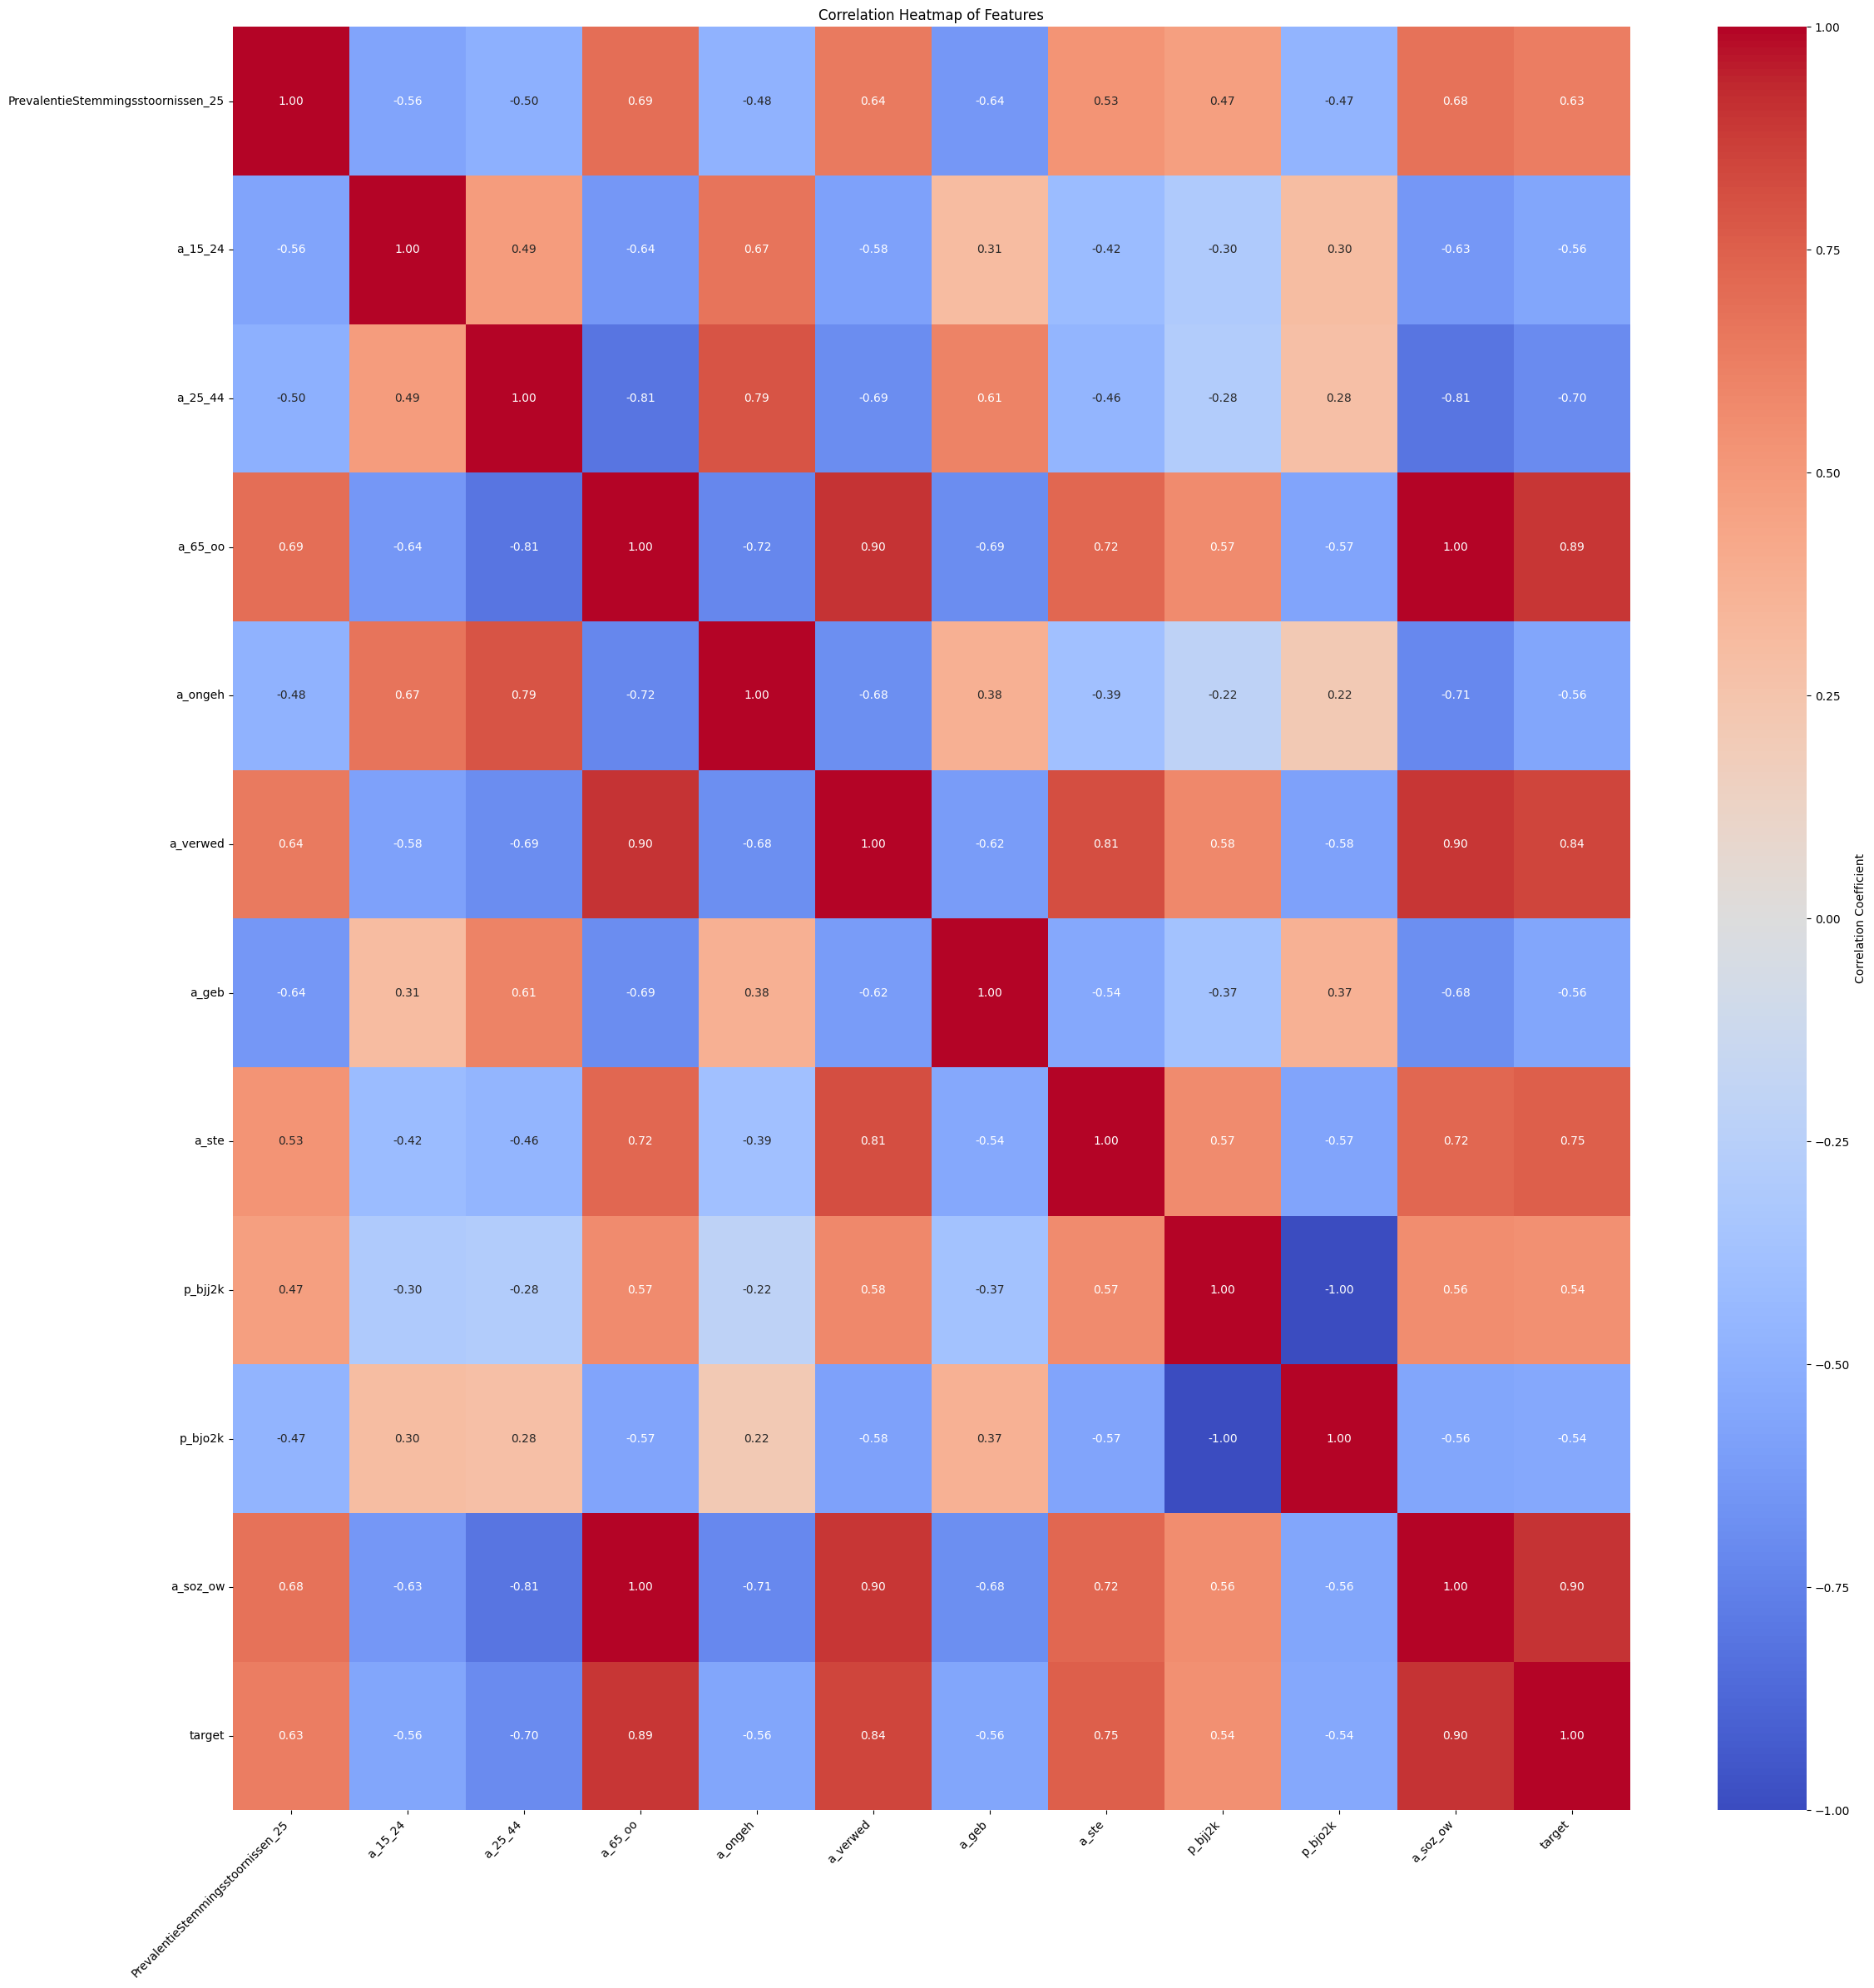

In [ ]:
# Compute the correlation matrix
correlation_matrix = df[features + [target]].corr().dropna(how="all").dropna(how="all", axis=1)

# Create the heatmap
plt.figure(figsize=(24, 24))
sns.heatmap(
    correlation_matrix,
    annot=True,           # Display the correlation values
    fmt=".2f",            # Format the annotation to 2 decimal places
    cmap="coolwarm",      # Use the coolwarm colormap
    cbar_kws={"label": "Correlation Coefficient"}
)

# Add titles and adjust layout
plt.title("Correlation Heatmap of Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# regression function

In [ ]:
def run_regression_print(scaler, model, param_grid, X_train, X_test, y_train, y_test):
  # Fit the model on the training data
  pipeline = make_pipeline(scaler, model)
  gs = GridSearchCV(pipeline, param_grid, cv=5)
  gs.fit(X_train, y_train)


  # Evaluate on the test set using the best model
  best_estimator = gs.best_estimator_
  y_test_pred = best_estimator.predict(X_test)

  # Evaluate performance

  mse_test = mean_squared_error(y_test, y_test_pred)
  r2_test = r2_score(y_test, y_test_pred)

  print('MSE test for ', model, ' with scaler ', scaler, ': ', mse_test)
  print('R2 test for ', model, ' with scaler ', scaler, ': ', r2_test)

In [ ]:
def run_regression(scaler, model, param_grid, X_train, X_test, y_train, y_test):
  # Fit the model on the training data
  pipeline = make_pipeline(scaler, model)
  gs = GridSearchCV(pipeline, param_grid, cv=5)
  gs.fit(X_train, y_train)

  # Evaluate on the test set using the best model
  best_estimator = gs.best_estimator_
  y_test_pred = best_estimator.predict(X_test)

  # Evaluate performance

  mse_test = mean_squared_error(y_test, y_test_pred)
  r2_test = r2_score(y_test, y_test_pred)

  return mse_test, r2_test

In [ ]:
def run_regression_param_print(scaler, model, param_grid, X_train, X_test, y_train, y_test):
  # Fit the model on the training data
  pipeline = make_pipeline(scaler, model)
  gs = GridSearchCV(pipeline, param_grid, cv=5)
  gs.fit(X_train, y_train)

  # Get the best alpha and cross-validation score
  best_params = gs.best_params_

  # Evaluate on the test set using the best model
  best_estimator = gs.best_estimator_
  y_test_pred = best_estimator.predict(X_test)

  # Evaluate performance

  mse_test = mean_squared_error(y_test, y_test_pred)
  r2_test = r2_score(y_test, y_test_pred)

  print('MSE test for ', model, ' with scaler ', scaler, ': ', mse_test)
  print('R2 test for ', model, ' with scaler ', scaler, ': ', r2_test)
  print('Best params: ', best_params)

In [ ]:
# Separate features (X) and target (y)
X = df[features]
y = df[target]

# Split the dataset into training, validation and testing sets (60/20/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

In [ ]:
# Choosing model and Scaler based on metrics for test set
run_regression_print(MinMaxScaler(), Lasso(max_iter=100000), {"lasso__alpha": np.logspace(-6, 2, 50)}, X_train, X_test, y_train, y_test)
run_regression_print(StandardScaler(), Lasso(max_iter=100000), {"lasso__alpha": np.logspace(-6, 2, 50)}, X_train, X_test, y_train, y_test)
run_regression_print(MinMaxScaler(), ElasticNet(max_iter=100000), {"elasticnet__alpha": np.logspace(-3, 0, 14), "elasticnet__l1_ratio": np.logspace(-3, 0, 10)}, X_train, X_test, y_train, y_test)
run_regression_print(StandardScaler(), ElasticNet(max_iter=100000), {"elasticnet__alpha": np.logspace(-3, 0, 14), "elasticnet__l1_ratio": np.logspace(-3, 0, 10)}, X_train, X_test, y_train, y_test)

MSE test for  Lasso(max_iter=100000)  with scaler  MinMaxScaler() :  5.227132682807746e-07
R2 test for  Lasso(max_iter=100000)  with scaler  MinMaxScaler() :  0.8477959712600021
MSE test for  Lasso(max_iter=100000)  with scaler  StandardScaler() :  5.281128742758922e-07
R2 test for  Lasso(max_iter=100000)  with scaler  StandardScaler() :  0.8462237100683767
MSE test for  ElasticNet(max_iter=100000)  with scaler  MinMaxScaler() :  4.920559494127705e-07
R2 test for  ElasticNet(max_iter=100000)  with scaler  MinMaxScaler() :  0.8567227916130117
MSE test for  ElasticNet(max_iter=100000)  with scaler  StandardScaler() :  5.125922826987526e-07
R2 test for  ElasticNet(max_iter=100000)  with scaler  StandardScaler() :  0.8507430071855867


# DBSCAN

In [ ]:
#PCA. will be needed later for visualisation
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train)
pca_components = pca.components_
X_train_pca.shape

(207, 2)

In [ ]:
#choosing best parameters for DBSCSN (chosen based on r2_valid)
eps_list = [0.5,1,2,3,4,5,6,7]
min_samples_list = [1,2,3,4,5,6,7]
r2_valid_list = np.zeros((len(eps_list), len(min_samples_list)))
for eps in eps_list:
  for min_samples in min_samples_list:
    X_train_copy = X_train.copy()
    y_train_copy = y_train.copy()
    clustering = make_pipeline(MinMaxScaler(), DBSCAN(eps=eps, min_samples=min_samples)).fit(X_train_copy)
    labels = clustering.named_steps['dbscan'].labels_
    X_train_copy["DBSCANLabel" + "_" + str(eps) + "_" + str(min_samples)] = labels
    samples_to_remove = X_train_copy[X_train_copy['DBSCANLabel' + "_" + str(eps) + "_" + str(min_samples)] == -1].index
    X_train_copy = X_train_copy.drop(samples_to_remove)
    y_train_copy = y_train_copy.drop(samples_to_remove)
    X_train_copy = X_train_copy.drop(columns=['DBSCANLabel' + "_" + str(eps) + "_" + str(min_samples)])
    mse_valid, r2_valid = run_regression(MinMaxScaler(), ElasticNet(max_iter=100000), {"elasticnet__alpha": np.logspace(-3, 0, 14), "elasticnet__l1_ratio": np.logspace(-3, 0, 10)}, X_train_copy, X_valid, y_train_copy, y_valid)
    r2_valid_list[eps_list.index(eps), min_samples_list.index(min_samples)] = r2_valid


In [ ]:
print(r2_valid_list)

[[0.8563568  0.87410339 0.87410339 0.87410339 0.87689478 0.87689478
  0.87689478]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]
 [0.8563568  0.8563568  0.8563568  0.8563568  0.8563568  0.8563568
  0.8563568 ]]


In [ ]:
eps_idx, min_sampes_idx = np.unravel_index(np.argmax(r2_valid_list), r2_valid_list.shape)

In [ ]:
eps = eps_list[eps_idx]
min_samples = min_samples_list[min_sampes_idx]
print(eps, min_samples)

0.5 5


Maximum R² Value: 0.8768947818017662
Best eps: 0.5
Best min_samples: 5


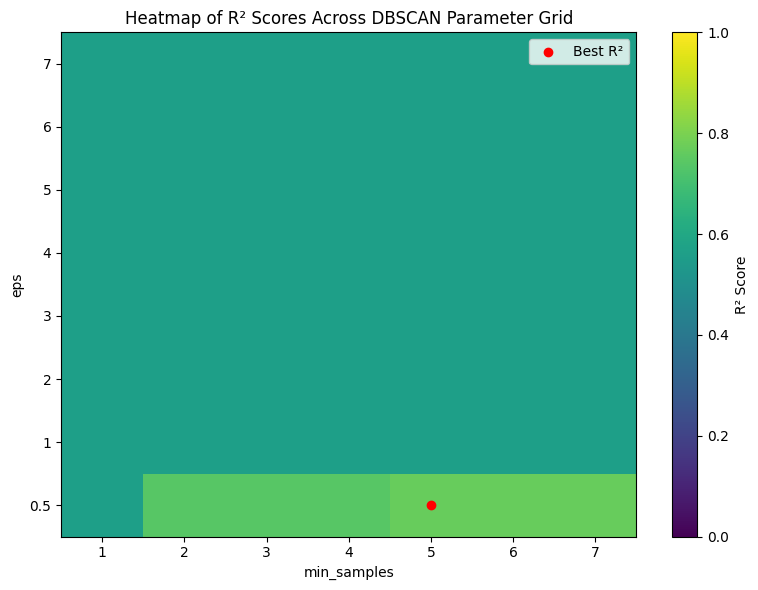

In [ ]:
max_r2_value = np.max(r2_valid_list)
eps_idx, min_samples_idx = np.unravel_index(np.argmax(r2_valid_list), r2_valid_list.shape)

eps = eps_list[eps_idx]
min_samples = min_samples_list[min_samples_idx]

print("Maximum R² Value:", max_r2_value)
print("Best eps:", eps)
print("Best min_samples:", min_samples)

plt.figure(figsize=(8, 6))
plt.imshow(r2_valid_list, cmap='viridis', aspect='auto', origin='lower', vmin=0.8, vmax=0.9)

plt.xticks(ticks=np.arange(len(min_samples_list)), labels=min_samples_list)
plt.yticks(ticks=np.arange(len(eps_list)), labels=eps_list)

# Highlight the best parameter combination
plt.scatter(min_samples_idx, eps_idx, color='red', label='Best R²')

plt.xlabel('min_samples')
plt.ylabel('eps')
plt.title('Heatmap of R² Scores Across DBSCAN Parameter Grid')
plt.colorbar(label='R² Score')
plt.legend()

plt.tight_layout()
plt.show()

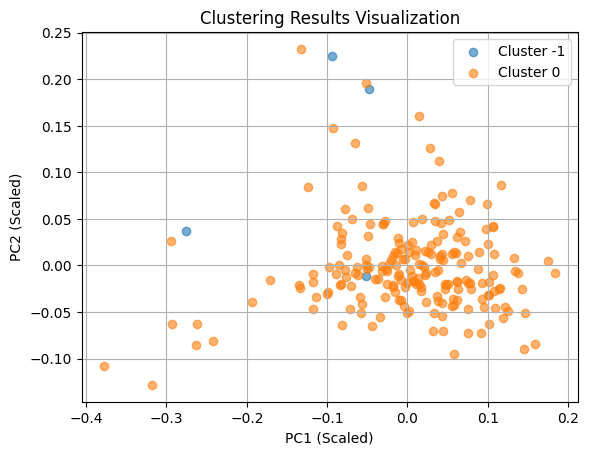

MSE test for  ElasticNet(max_iter=100000)  with scaler  MinMaxScaler() :  5.278117136876189e-07
R2 test for  ElasticNet(max_iter=100000)  with scaler  MinMaxScaler() :  0.846311402226993
Best params:  {'elasticnet__alpha': 0.001, 'elasticnet__l1_ratio': 0.001}


In [ ]:
X_train_copy = X_train.copy()
y_train_copy = y_train.copy()
clustering = make_pipeline(MinMaxScaler(), DBSCAN(eps=eps, min_samples=min_samples)).fit(X_train_copy)
labels = clustering.named_steps['dbscan'].labels_

unique_labels = np.unique(labels)

for label in unique_labels:
    cluster_points = X_train_pca[labels == label]
    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        label=f"Cluster {label}",
        alpha=0.6,
    )

plt.title("Clustering Results Visualization")
plt.xlabel("PC1 (Scaled)")
plt.ylabel("PC2 (Scaled)")
plt.legend()
plt.grid(True)
plt.show()

X_train_copy["DBSCANLabel" + "_" + str(eps) + "_" + str(min_samples)] = labels
samples_to_remove = X_train_copy[X_train_copy['DBSCANLabel' + "_" + str(eps) + "_" + str(min_samples)] == -1].index
X_train_copy = X_train_copy.drop(samples_to_remove)
y_train_copy = y_train_copy.drop(samples_to_remove)
X_train_copy = X_train_copy.drop(columns=['DBSCANLabel' + "_" + str(eps) + "_" + str(min_samples)])
run_regression_param_print(MinMaxScaler(), ElasticNet(max_iter=100000), {"elasticnet__alpha": np.logspace(-3, 0, 14), "elasticnet__l1_ratio": np.logspace(-3, 0, 10)}, X_train_copy, X_test, y_train_copy, y_test)